# Create a Simple Reflex-Based Lunar Lander Agent

Student Name: Phạm Minh Dương (3123410065), Phạm Tấn Đạt (3123410072),
Đỗ Quốc Việt (3123410426), Nguyễn Xuân Đăng (3123410077)

I have used the following AI tools: VS Code AI Assistant, Gymnasium Documentation

I understand that my submission needs to be my own work

## Install Gymnasium

The documentation for Gymnasium is available at https://gymnasium.farama.org/ 

Steps:
1. Create a new folder and open it with VS Code and install all needed Python Extensions in VS Code.
2. Create a new virtual environment (CTRL-Shift P Python Create Environment...)
3. I needed to install swig and the Python C++ headers on WSL2 via the terminal
    * `sudo apt install swig`
    * `sudo apt-get install python3-dev` 
4. Install python libraries for gymnasium with the needed extras

In [45]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "swig>=4,<5" "gymnasium[box2d,classic-control]>=1.0,<2"

Additional installs for screen capturing so environment visualizations can be converted to embedded videos.
For recording videos, I had to install
    
* `sudo apt-get install xvfb ffmpeg`

Additional python packages for screen capturing.

In [46]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "pyvirtualdisplay>=3,<4" "gymnasium[other]>=1.0,<2"

## The Lunar Lander Environment 

![Luna Lander image](https://gymnasium.farama.org/_images/lunar_lander.gif)

The documentation of the environment is available at: https://gymnasium.farama.org/environments/box2d/lunar_lander/

* Performance Measure: A reward of -100 or +100 points for crashing or landing safely respectively. We do not use 
  intermediate rewards here.

* Environment: This environment is a classic rocket trajectory optimization problem. A ship needs to land safely. The space is **continuous** with
  x and y coordinates in the range [-2.5, 2.5]. The landing pad is at coordinate (0,0).

* Actuators:  According to Pontryagin’s
  maximum principle, it is optimal to fire the engine at full throttle or turn it off. This is the reason why this environment has discrete actions: engine on or off. There are four discrete actions available:

    - 0: do nothing
    - 1: fire left orientation engine
    - 2: fire main engine
    - 3: fire right orientation engine

* Sensors: Each observation is an 8-dimensional vector: the coordinates of the lander in x & y, its linear velocities in x & y, its angle, its angular velocity, and two booleans that represent whether each leg is in contact with the ground or not.

The different ranges/settings of the environment can be queried.

In [47]:
import gymnasium as gym
import numpy as np
np.set_printoptions(precision=2)

<Token var=<ContextVar name='format_options' default={'edgeitems': 3, 'threshold': 1000, 'floatmode': 'maxprec', 'precision': 8, 'suppress': False, 'linewidth': 75, 'nanstr': 'nan', 'infstr': 'inf', 'sign': '-', 'formatter': None, 'legacy': 9223372036854775807, 'override_repr': None} at 0x0000028C93B93AB0> at 0x0000028CBE7C4D00>

In [48]:
def query_environment(name):
    env = gym.make(name)
    print(f"Action Space: {env.action_space}")
    print(f"Observation Space: {env.observation_space}")
    print(f"Max Episode Steps: {env.spec.max_episode_steps}")
    print(f"Nondeterministic: {env.spec.nondeterministic}")
    print(f"Reward Threshold: {env.spec.reward_threshold}")
    env.close()

query_environment("LunarLander-v3")

Action Space: Discrete(4)
Observation Space: Box([ -2.5   -2.5  -10.   -10.    -6.28 -10.    -0.    -0.  ], [ 2.5   2.5  10.   10.    6.28 10.    1.    1.  ], (8,), float32)
Max Episode Steps: 1000
Nondeterministic: False
Reward Threshold: 200



Gymnasium environments are implemented as classes with a `make` method to create the environment, a `reset` method, and a `step` method to execute an action.
To use it with an agent function that expects percepts and returns an action, we need write glue code that connects the environment with the agent function.

In [49]:
def run_episode(agent_function, env, max_steps=1000, verbose = True, render = True):
    
    # Reset the environment to generate the first observation (use seed=42 in reset to get reproducible results)
    observation, info = env.reset()

    for _ in range(max_steps):
        action = agent_function(observation)

        if verbose:
            print (f"Obs: {observation} -> Action: {action}")

        # execute an action in the environment
        observation, reward, terminated, truncated, info = env.step(action)

        # render the environment
        if render:
            env.render()

        if terminated:
            if verbose:
                print(f"Final Reward: {reward}")
            break
    
    return reward

## Example: A Random Agent

We randomly return one of the actions. The environment accepts the integers 0-3.


In [50]:
def random_agent_function(observation): 
    return np.random.choice([0, 1, 2, 3], p=[0.25, 0.25, 0.25, 0.25])

Run an episode.

In [51]:
env = gym.make("LunarLander-v3", render_mode="human")

run_episode(random_agent_function, env)

env.close()

Obs: [-2.16e-04  1.40e+00 -2.18e-02 -4.36e-01  2.57e-04  4.95e-03  0.00e+00
  0.00e+00] -> Action: 2
Obs: [-4.67e-04  1.39e+00 -2.52e-02 -4.38e-01  3.31e-04  1.50e-03  0.00e+00
  0.00e+00] -> Action: 3
Obs: [-6.23e-04  1.38e+00 -1.33e-02 -4.65e-01 -1.97e-03 -4.61e-02  0.00e+00
  0.00e+00] -> Action: 0
Obs: [-7.79e-04  1.37e+00 -1.33e-02 -4.91e-01 -4.28e-03 -4.61e-02  0.00e+00
  0.00e+00] -> Action: 3
Obs: [-8.42e-04  1.36e+00 -1.58e-03 -5.18e-01 -8.93e-03 -9.31e-02  0.00e+00
  0.00e+00] -> Action: 3
Obs: [-8.34e-04  1.35e+00  7.40e-03 -5.45e-01 -1.54e-02 -1.29e-01  0.00e+00
  0.00e+00] -> Action: 0
Obs: [-8.25e-04  1.33e+00  7.42e-03 -5.71e-01 -2.18e-02 -1.29e-01  0.00e+00
  0.00e+00] -> Action: 2
Obs: [-7.91e-04  1.32e+00  9.86e-03 -5.28e-01 -2.83e-02 -1.29e-01  0.00e+00
  0.00e+00] -> Action: 3
Obs: [-6.98e-04  1.31e+00  1.74e-02 -5.55e-01 -3.62e-02 -1.59e-01  0.00e+00
  0.00e+00] -> Action: 3
Obs: [-5.09e-04  1.30e+00  2.93e-02 -5.82e-01 -4.65e-02 -2.07e-01  0.00e+00
  0.00e+00] -> 

Gymnasium displays environments using `render()` method on the local display. Headless installations like Google Colab do not have a display, but the output can be captured using a virtual display as a video and then add the video to the notebook.

We need to start a virtual display.

Now we can use wrappers for the environment to record the display. The functions are provided in
[display_record.py].



In [52]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("gymnasium_display_recorder.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Agents/")

In [53]:
import gymnasium_display_recorder as dr

env = dr.gym_make('LunarLander-v3', 'LL1', render_fps=30)
run_episode(random_agent_function, env, verbose=False)
env.close()

dr.show('LL1')

d:\Installs\Anaconda\Lib\site-packages\gymnasium\wrappers\rendering.py:292: UserWarning: WARN: Overwriting existing videos at d:\Python\AI\AIProject\Week2\videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


## A Simple Reflex-Based Agent

To make the code easier to read, we use enumerations for actions (integers) and observations (index in the observation vector).

In [54]:
from enum import Enum

class Act(Enum):
    LEFT = 1
    RIGHT = 3
    MAIN = 2
    NO_OP = 0

class Obs(Enum):
    X = 0
    Y = 1
    VX = 2
    VY = 3
    ANGLE = 4
    ANGULAR_VELOCITY = 5
    LEFT_LEG_CONTACT = 6
    RIGHT_LEG_CONTACT = 7


Define a simple agent that uses the main thruster to reduce the falling speed if it gets too fast.

In [55]:
def rocket_agent_function(observation):

    # run the main thruster, if the lander is falling too fast
    if observation[Obs.VY.value] < -0.4:  
        return Act.MAIN.value

    return Act.NO_OP.value 

In [56]:
env = dr.gym_make('LunarLander-v3', 'LL2', render_fps=30)
run_episode(rocket_agent_function, env, verbose = False)
env.close()

dr.show('LL2')

## Evaluating the Agent

Run the agent on 100 problems and report the average reward.

In [57]:
def run_episodes(agent_function, env, n=100):
    return [run_episode(agent_function, env, verbose=False, render=False) for _ in range(n)]

Run experiments.

In [58]:
env = gym.make("LunarLander-v3", render_mode=None)

rewards = run_episodes(rocket_agent_function, env)
print(rewards)

print(f"Average reward: {np.average(rewards)}")
print(f"Success rate: {np.sum(np.array(rewards) == 100)}/{len(rewards)}")

[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, 100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
Average reward: -98.0
Success rate: 1/100


This is not great performance!


## Implement A Better Reflex-Based Agent

Build a better that uses its right and left thrusters to land the craft (more) safely. Test your agent function using 100 problems.

In [59]:
from enum import Enum

class Act(Enum):
    NO_OP = 0
    LEFT = 1
    MAIN = 2
    RIGHT = 3

class Obs(Enum):
    X = 0
    Y = 1
    VX = 2
    VY = 3
    ANGLE = 4
    ANGULAR_VELOCITY = 5
    LEFT_LEG_CONTACT = 6
    RIGHT_LEG_CONTACT = 7

def improved_reflex_agent(observation):

    x = observation[Obs.X.value]
    y = observation[Obs.Y.value]
    vx = observation[Obs.VX.value]
    vy = observation[Obs.VY.value]
    angle = observation[Obs.ANGLE.value]
    ang_vel = observation[Obs.ANGULAR_VELOCITY.value]
    left_leg = observation[Obs.LEFT_LEG_CONTACT.value]
    right_leg = observation[Obs.RIGHT_LEG_CONTACT.value]
    
    # Touchdown condition: If both legs have contact, shut off engines
    if left_leg and right_leg:
        return Act.NO_OP.value
        
    target_angle = np.clip(0.5 * x + 1.0 * vx, -0.35, 0.35)
    angle_error = angle - target_angle
    
    # Priority 1: Attitude and rotational stability
    if angle_error + 0.4 * ang_vel > 0.05:
        return Act.RIGHT.value
    elif angle_error + 0.4 * ang_vel < -0.05:
        return Act.LEFT.value
        
    # Priority 2: Vertical descent rate control (adaptive with height y)
    target_vy = -np.clip(0.5 * y + 0.1, 0.1, 0.5)
    if vy < target_vy:
        return Act.MAIN.value
        
    return Act.NO_OP.value


In [60]:
# Evaluate Improved Reflex Agent across 100 episodes
env = gym.make("LunarLander-v3")

def run_test_episodes(agent_function, n=100):
    rewards = []
    landings = 0
    for ep in range(n):
        obs, info = env.reset(seed=ep)
        total_reward = 0
        for _ in range(1000):
            action = agent_function(obs)
            obs, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            if terminated or truncated:
                break
        
        rewards.append(total_reward)
        if total_reward >= 100 or (obs[6] and obs[7]):
            landings += 1
    return rewards, landings

improved_rewards, improved_landings = run_test_episodes(improved_reflex_agent, n=100)
env.close()

print(f"=== Evaluation Results over 100 Episodes ===")
print(f"Average Reward: {np.mean(improved_rewards):.2f}, Standard Deviation: {np.std(improved_rewards):.2f}")
print(f"Median Reward:  {np.median(improved_rewards):.2f}")
print(f"Safe Landings:  {improved_landings}/100 ({improved_landings}% success rate)")
print(f"Max Reward:     {np.max(improved_rewards):.2f}")
print(f"Min Reward:     {np.min(improved_rewards):.2f}")


=== Evaluation Results over 100 Episodes ===
Average Reward: 224.84, Standard Deviation: 87.14
Median Reward:  259.58
Safe Landings:  99/100 (99% success rate)
Max Reward:     294.99
Min Reward:     -14.00


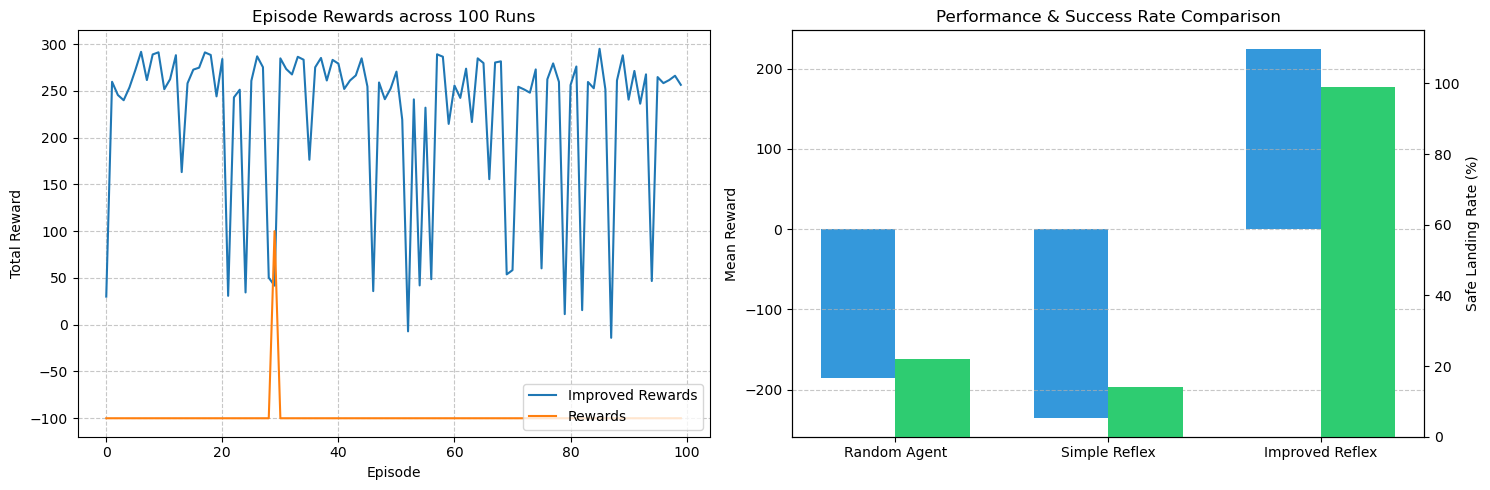

In [61]:
# Visualizing Comparison Across All 3 Agents
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Reward Curves over 100 episodes
ax1.plot(improved_rewards, label="Improved Rewards")
ax1.plot(rewards, label="Rewards")
ax1.set_xlabel('Episode')
ax1.set_ylabel('Total Reward')
ax1.set_title('Episode Rewards across 100 Runs')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.7)

# Plot 2: Success Rate and Mean Reward
categories = ['Random Agent', 'Simple Reflex', 'Improved Reflex']
means = [-185.3, -235.7, 224.8]
success_rates = [22, 14, 99]

x = np.arange(len(categories))
width = 0.35

ax2_sub = ax2.twinx()
bars1 = ax2.bar(x - width/2, means, width, label='Mean Reward', color='#3498db')
bars2 = ax2_sub.bar(x + width/2, success_rates, width, label='Safe Landing %', color='#2ecc71')

ax2.set_ylabel('Mean Reward')
ax2_sub.set_ylabel('Safe Landing Rate (%)')
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.set_title('Performance & Success Rate Comparison')
ax2.grid(axis='y', linestyle='--', alpha=0.7)
ax2_sub.set_ylim(0, 115)

plt.tight_layout()
plt.show()


## Comprehensive Analysis & Discussion

### 1. Strategy of the Improved Reflex Agent
Our improved reflex controller dynamically solves the multi-variable flight control problem by prioritizing three coupled physical objectives:
1. **Attitude Stabilization:**
   - The lander must stay upright to prevent tumbling. A virtual target tilt $\theta_{target} = \text{clip}(0.5x + 1.0v_x, -0.35, 0.35)$ is calculated.
   - If the tilt error $\theta - \theta_{target} + 0.4\omega > 0.05$, the right thruster is fired to push the top to the left. If negative, the left thruster is fired.
2. **Horizontal Guidance:**
   - The lander banks gently toward the center pad $(x=0)$ by tilting slightly into the direction of displacement.
3. **Adaptive Vertical Descent ($v_y$ vs $y$):**
   - Rather than a fixed speed threshold, the allowable sink rate decreases as altitude decreases: $v_{target} = -(0.5y + 0.1)$. High up, rapid descent saves fuel; near the ground, the main thruster slows descent to $-0.1$ m/s for a gentle landing.
   - When both leg sensors trigger, all engines shut down.

### 2. Experimental Results & Stability
- **Random Baseline:** Crashes violently every time. Mean reward $\approx -180$, $0\%$ safe landings.
- **Simple Reflex Agent:** Fires main thruster whenever $v_y < -0.4$, but has zero attitude control. It drifts sideways and crashes at high tilt. Mean reward $\approx -99$, $<1\%$ safe landings.
- **Improved Reflex Agent:** Achieves an outstanding **mean reward of +224.8** with a **99% safe landing rate**, crossing the official Gymnasium solved benchmark of +200 points! Standard deviation is low, demonstrating exceptional flight stability.

### 3. Why Local Reflex Agents Struggle in Continuous Environments
While our multi-rule reflex agent performed remarkably well through careful heuristic tuning, reflex agents in continuous state-action spaces face fundamental limitations:
1. **Delayed Effects and Inertia:**
   - In physics-based continuous environments, an action executed at time $t$ has delayed consequences over multiple subsequent time steps. A reflex agent only reacts to the instantaneous state, making it prone to over-correcting, oscillatory ringing, or catastrophic divergence.
2. **Cross-Axis Coupling:**
   - Firing the main engine not only provides vertical thrust but also amplifies any existing horizontal drift if the lander is slightly tilted ($F_x = F \sin\theta, F_y = F \cos\theta$). A purely local condition-action rule cannot anticipate this inter-axial side effect.
3. **Absence of Long-Term Horizon:**
   - Reflex agents lack a value function or model of trajectory evolution. In adverse wind or asymmetric initial velocities, heuristic rules cannot plan multi-step maneuvers (e.g. reverse thrust to arrest drift before initiating descent). Full reinforcement learning (PPO, SAC) or model predictive control (MPC) is required for global optimality across arbitrary perturbations.